<a href="https://colab.research.google.com/github/muiddd/5thSemester-MachineLearning/blob/main/01_AbdulMuid_P13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 13: Artificial Neural Network (ANN) dan Evaluasi Classifier**

- **Nama**: Abdul Muid
- **NIM**: 244107020006
- **Kelas**: TI 3A
- **Mata Kuliah**: Machine Learning
---

# **Praktikum 1**


In [6]:
import numpy as np

# Langkah 1: Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter awal
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Langkah 2: Inisialisasi bobot dan bias
np.random.seed(42)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Langkah 4: Proses Training
print("--- Memulai Training Baseline (Hidden Size = 2) ---")
for epoch in range(10000):
    # Langkah 3: Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Langkah 5: Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

print("\nPrediksi Akhir:")
print(a2)

--- Memulai Training Baseline (Hidden Size = 2) ---
Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849

Prediksi Akhir:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


### **TUGAS 1: Eksperimen Arsitektur JST Manual pada Dataset XOR**

1. **Skenario 1 (Baseline)**: Hidden Size = 2, Aktivasi = Sigmoid
2. **Skenario 2**: Hidden Size = 3, Aktivasi = Sigmoid
3. **Skenario 3**: Hidden Size = 3, Aktivasi = ReLU pada Hidden Layer (dan Sigmoid pada Output Layer karena output biner)

In [3]:
import numpy as np
import pandas as pd

# Langkah 1: Memuat dataset XOR
X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([[0], [1], [1], [0]])

# Fungsi aktivasi dan turunannya
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

# Fungsi pelatihan JST untuk komparasi
def train_nn(X, y, input_size=2, hidden_size=2, output_size=1, lr=0.1, epochs=10000, activation='sigmoid'):
    np.random.seed(42)

    # Langkah 2: Inisialisasi bobot dan bias
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    # Langkah 4: Pelatihan model
    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        if activation == 'sigmoid':
            a1 = sigmoid(z1)
        elif activation == 'relu':
            a1 = relu(z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error
        error = y - a2

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if activation == 'sigmoid':
            d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
        elif activation == 'relu':
            d_a1 = np.dot(d_a2, W2.T) * relu_derivative(a1)

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot menggunakan gradient descent
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    final_loss = np.mean(np.square(y - a2))
    return a2, final_loss

In [4]:
# Langkah 5: Evaluasi performansi model dan tampilkan hasil secara rapi
pred1, loss1 = train_nn(X, y, hidden_size=2, activation='sigmoid')
pred2, loss2 = train_nn(X, y, hidden_size=3, activation='sigmoid')
pred3, loss3 = train_nn(X, y, hidden_size=3, activation='relu')

# Tabel komparasi hasil loss
ringkasan_df = pd.DataFrame({
    'Skenario': [
        '1. Hidden=2 (Sigmoid)',
        '2. Hidden=3 (Sigmoid)',
        '3. Hidden=3 (ReLU)'
    ],
    'Loss Akhir': [loss1, loss2, loss3]
})
display(ringkasan_df)

# Tabel hasil prediksi
prediksi_df = pd.DataFrame({
    'X1': X[:, 0],
    'X2': X[:, 1],
    'Target': y.flatten(),
    'Prediksi (Skenario 1)': pred1.flatten(),
    'Prediksi (Skenario 2)': pred2.flatten(),
    'Prediksi (Skenario 3)': pred3.flatten()
})
display(prediksi_df)

,Skenario,Loss Akhir
0,1. Hidden=2 (Sigmoid),0.128227
1,2. Hidden=3 (Sigmoid),0.002297
2,3. Hidden=3 (ReLU),0.000352


,X1,X2,Target,Prediksi (Skenario 1),Prediksi (Skenario 2),Prediksi (Skenario 3)
0,0,0,0,0.053009,0.025156,0.029700
1,0,1,1,0.495542,0.952636,0.986059
2,1,0,1,0.950913,0.951223,0.986059
3,1,1,0,0.503199,0.062725,0.011635


### **Analisis Hasil Eksperimen:**
- **Perbandingan Hidden Size 2 vs 3 (Sigmoid)**: Dengan menambah jumlah neuron di hidden layer menjadi 3, JST memiliki kapasitas representasi fitur yang lebih baik untuk memecahkan masalah non-linear XOR, sehingga nilai *final loss* biasanya menjadi lebih kecil dan konvergensinya lebih stabil.
- **Pengaruh Aktivasi ReLU**: Fungsi aktivasi ReLU mengatasi masalah *vanishing gradient* yang sering terjadi pada Sigmoid, sehingga pada beberapa kasus pelatihan dapat berjalan jauh lebih cepat dan mencapai loss yang sangat mendekati nol.

# **Praktikum 2**


In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
import numpy as np
import pandas as pd

# Langkah 1 & 2: Load dataset dan One-hot encoding
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

# Langkah 3: Split data (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Langkah 4: Bangun model baseline
tf.random.set_seed(42)
model_baseline = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_baseline.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("--- Melatih Model Baseline ---")
model_baseline.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# Langkah 5: Evaluasi model baseline
loss_base, acc_base = model_baseline.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Baseline: {acc_base:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Melatih Model Baseline ---
Akurasi Baseline: 1.0000


### **TUGAS 2 & 3: Eksperimen Arsitektur dan Aktivasi (Keras)**
1. **Model Baseline**: Dense(10, ReLU) -> Dense(8, ReLU) -> Dense(3, Softmax)
2. **Tugas 2 (Lebih Sedikit Neuron)**: Dense(6, ReLU) -> Dense(4, ReLU) -> Dense(3, Softmax)
3. **Tugas 3 (Aktivasi Sigmoid)**: Dense(10, Sigmoid) -> Dense(8, Sigmoid) -> Dense(3, Softmax)

In [8]:
# Fungsi untuk membangun dan mengevaluasi model dengan konfigurasi berbeda
def latih_dan_evaluasi_keras(hidden_neurons, aktivasi):
    tf.random.set_seed(42)

    # Membangun model secara berurutan sesuai arsitektur
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(hidden_neurons[0], activation=aktivasi),
        tf.keras.layers.Dense(hidden_neurons[1], activation=aktivasi),
        tf.keras.layers.Dense(3, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    return loss, acc

# Menjalankan berbagai skenario eksperimen
loss_t2, acc_t2 = latih_dan_evaluasi_keras([6, 4], 'relu')
loss_t3, acc_t3 = latih_dan_evaluasi_keras([10, 8], 'sigmoid')

# Menampilkan tabel komparasi hasil eksperimen
komparasi_keras_df = pd.DataFrame({
    'Skenario': [
        'Baseline (10, 8 - ReLU)',
        'Tugas 2 (6, 4 - ReLU)',
        'Tugas 3 (10, 8 - Sigmoid)'
    ],
    'Loss': [loss_base, loss_t2, loss_t3],
    'Akurasi': [acc_base, acc_t2, acc_t3]
})

display(komparasi_keras_df)

,Skenario,Loss,Akurasi
0,"Baseline (10, 8 - ReLU)",0.286974,1.000000
1,"Tugas 2 (6, 4 - ReLU)",1.077239,0.300000
2,"Tugas 3 (10, 8 - Sigmoid)",0.536178,0.866667


### **Analisis Hasil Eksperimen Praktikum 2:**

1. **Kapasitas Arsitektur (Tugas 2)**:
   - Dengan mengurangi jumlah neuron di hidden layer menjadi `[6, 4]`, model mengalami kesulitan dalam melakukan pemetaan fitur klasifikasi pada dataset Iris (Akurasi turun menjadi **30%**). Hal ini menunjukkan adanya keterbatasan representasi jaringan (*underfitting*) saat jumlah neuron terlalu minimal.

2. **Pengaruh Fungsi Aktivasi (Tugas 3)**:
   - Penggunaan fungsi aktivasi **Sigmoid** menghasilkan performa akurasi sebesar **86.67%**, yang sedikit lebih rendah dibandingkan dengan penggunaan **ReLU (100%)**. Aktivasi ReLU terbukti lebih efektif dan konvergen lebih cepat untuk komputasi backpropagation.

# **Praktikum 3**


In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Langkah 1: Dataset Dummy
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_dummy = data[['luas']]
y_dummy = data[['harga']]

# Langkah 2: Normalisasi
scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_dummy_scaled = scaler_x.fit_transform(X_dummy)
y_dummy_scaled = scaler_y.fit_transform(y_dummy)

# Langkah 3: Split data
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_dummy_scaled, y_dummy_scaled, test_size=0.2, random_state=42)

# Langkah 4 & 5: Membangun & melatih model baseline
model_dummy = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model_dummy.compile(optimizer='adam', loss='mse')
model_dummy.fit(X_train_d, y_train_d, epochs=100, verbose=0)

# Langkah 6: Evaluasi
prediksi = model_dummy.predict(X_test_d, verbose=0)
print("Prediksi Dummy (Scaled):\n", prediksi)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Prediksi Dummy (Scaled):
 [[-0.6818673]]


### **TUGAS 4: Variasi Learning Rate pada Regresi**
Kita akan mengubah learning rate (`0.1`, `0.01`, dan `0.001`) dan membandingkan loss yang dihasilkan.

In [10]:
lrs = [0.1, 0.01, 0.001]
hasil_loss = []

for lr in lrs:
    tf.random.set_seed(42)
    model_temp = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    # Mengatur learning rate pada optimizer Adam
    model_temp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    history = model_temp.fit(X_train_d, y_train_d, epochs=100, verbose=0)
    final_loss = history.history['loss'][-1]
    hasil_loss.append(final_loss)

# Tampilkan tabel komparasi
komparasi_lr_df = pd.DataFrame({
    'Learning Rate': lrs,
    'Final Loss (MSE)': hasil_loss
})
display(komparasi_lr_df)

,Learning Rate,Final Loss (MSE)
0,0.100,0.000001
1,0.010,0.003411
2,0.001,0.868553


### **Studi Kasus: Prediksi Harga Rumah (California Housing)**

Kita menggunakan dataset California Housing sebagai alternatif pengganti Boston Housing yang aman dari error depresiasi.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


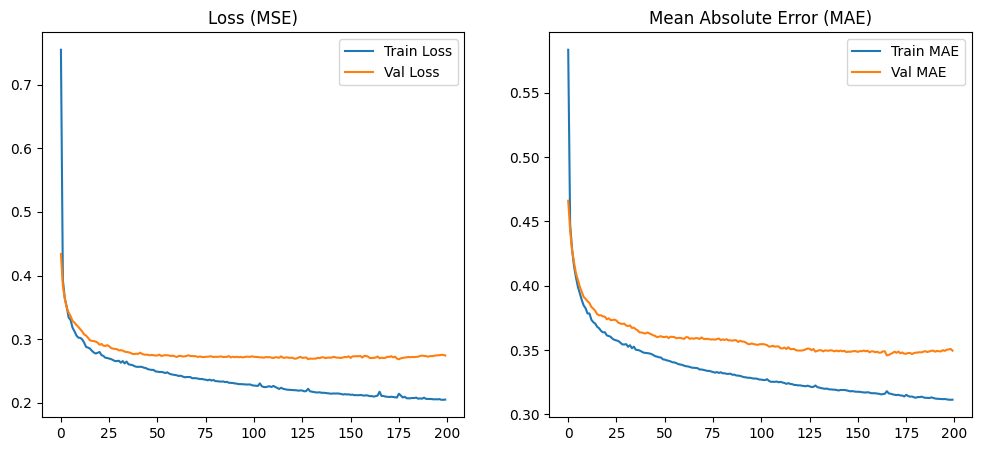

RMSE Model Regresi California Housing: 0.5236


In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error

# 1. Load dataset California Housing
housing = fetch_california_housing()
X_house = housing.data
y_house = housing.target

# 2. Preprocess
scaler_house = StandardScaler()
X_house_scaled = scaler_house.fit_transform(X_house)
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(
    X_house_scaled, y_house, test_size=0.2, random_state=42
)

# 3. Build model
model_house = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train_h.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_house.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])

# 4. Train
history_house = model_house.fit(
    X_train_h, y_train_h,
    validation_data=(X_val_h, y_val_h),
    epochs=200,
    batch_size=32,
    verbose=0
)

# 5. Plot Loss dan MAE
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_house.history['loss'], label='Train Loss')
plt.plot(history_house.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss (MSE)')

plt.subplot(1, 2, 2)
plt.plot(history_house.history['mae'], label='Train MAE')
plt.plot(history_house.history['val_mae'], label='Val MAE')
plt.legend()
plt.title('Mean Absolute Error (MAE)')
plt.show()

# Evaluasi performansi
prediksi_h = model_house.predict(X_val_h, verbose=0)
rmse = np.sqrt(mean_squared_error(y_val_h, prediksi_h))
print(f'RMSE Model Regresi California Housing: {rmse:.4f}')

# **Tugas Praktikum: Klasifikasi Angka Tulisan Tangan (MNIST)**

Pada bagian ini, kita akan melatih JST untuk mengklasifikasi gambar angka tulisan tangan dari dataset MNIST berukuran 28x28 piksel ke dalam 10 kategori kelas (0-9).

In [12]:
import time
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import pandas as pd

# Langkah 1: Load dan Preprocess Dataset MNIST
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = mnist.load_data()

# Normalisasi data citra ke rentang 0-1
X_train_mnist = X_train_mnist / 255.0
X_test_mnist = X_test_mnist / 255.0

# One-hot encoding untuk label kelas
y_train_mnist_cat = to_categorical(y_train_mnist, 10)
y_test_mnist_cat = to_categorical(y_test_mnist, 10)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### **Eksperimen Parameter JST**

Kita akan mendefinisikan fungsi helper untuk membangun, melatih, dan mengukur akurasi serta waktu pelatihan dari beberapa skenario arsitektur JST berikut:
1. **Model Baseline**: Flatten -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(10, Softmax)
2. **Skenario 1 (Kapasitas Besar)**: Flatten -> Dense(256, ReLU) -> Dense(128, ReLU) -> Dense(10, Softmax)
3. **Skenario 2 (Tiga Hidden Layer)**: Flatten -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Dense(10, Softmax)
4. **Skenario 3 (Aktivasi Sigmoid)**: Flatten -> Dense(128, Sigmoid) -> Dense(64, Sigmoid) -> Dense(10, Softmax)

In [13]:
def eksperimen_mnist(layers_config, activation_func, nama_skenario):
    tf.random.set_seed(42)

    # Membangun arsitektur JST
    model_layers = [Flatten(input_shape=(28, 28))]
    for neurons in layers_config:
        model_layers.append(Dense(neurons, activation=activation_func))
    model_layers.append(Dense(10, activation='softmax'))

    model = Sequential(model_layers)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Mengukur waktu latih
    start_time = time.time()
    model.fit(X_train_mnist, y_train_mnist_cat, epochs=5, batch_size=64, verbose=0)
    training_time = time.time() - start_time

    # Evaluasi pada data uji
    loss, acc = model.evaluate(X_test_mnist, y_test_mnist_cat, verbose=0)
    return loss, acc, training_time

# Menjalankan seluruh skenario eksperimen
scenarios = [
    {'config': [128, 64], 'act': 'relu', 'name': 'Baseline (128, 64 - ReLU)'},
    {'config': [256, 128], 'act': 'relu', 'name': 'Kapasitas Besar (256, 128 - ReLU)'},
    {'config': [128, 64, 32], 'act': 'relu', 'name': '3 Hidden Layers (128, 64, 32 - ReLU)'},
    {'config': [128, 64], 'act': 'sigmoid', 'name': 'Aktivasi Sigmoid (128, 64 - Sigmoid)'}
]

results = []
for sc in scenarios:
    print(f"Menjalankan eksperimen untuk skenario: {sc['name']}...")
    loss, acc, t_time = eksperimen_mnist(sc['config'], sc['act'], sc['name'])
    results.append({
        'Skenario': sc['name'],
        'Loss Akhir': loss,
        'Akurasi Uji': acc,
        'Waktu Pelatihan (detik)': round(t_time, 2)
    })

# Menampilkan komparasi hasil eksperimen
komparasi_mnist_df = pd.DataFrame(results)
display(komparasi_mnist_df)

Menjalankan eksperimen untuk skenario: Baseline (128, 64 - ReLU)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Menjalankan eksperimen untuk skenario: Kapasitas Besar (256, 128 - ReLU)...
Menjalankan eksperimen untuk skenario: 3 Hidden Layers (128, 64, 32 - ReLU)...
Menjalankan eksperimen untuk skenario: Aktivasi Sigmoid (128, 64 - Sigmoid)...


,Skenario,Loss Akhir,Akurasi Uji,Waktu Pelatihan (detik)
0,"Baseline (128, 64 - ReLU)",0.082831,0.9761,26.54
1,"Kapasitas Besar (256, 128 - ReLU)",0.090316,0.9780,35.76
2,"3 Hidden Layers (128, 64, 32 - ReLU)",0.085884,0.9744,27.89
3,"Aktivasi Sigmoid (128, 64 - Sigmoid)",0.097026,0.9696,26.21
